In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/alsaniipe/heart-disease/Index
/kaggle/input/datasets/alsaniipe/heart-disease/WARNING
/kaggle/input/datasets/alsaniipe/heart-disease/ask-detrano
/kaggle/input/datasets/alsaniipe/heart-disease/bak
/kaggle/input/datasets/alsaniipe/heart-disease/cleve.mod
/kaggle/input/datasets/alsaniipe/heart-disease/cleveland.data
/kaggle/input/datasets/alsaniipe/heart-disease/heart-disease.names
/kaggle/input/datasets/alsaniipe/heart-disease/hungarian.data
/kaggle/input/datasets/alsaniipe/heart-disease/long-beach-va.data
/kaggle/input/datasets/alsaniipe/heart-disease/new.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.cleveland.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.hungarian.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.switzerland.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.va.data
/kaggle/input/datasets/alsaniipe/heart-disease/reprocessed.hungarian.data
/kaggle/input/datasets/alsaniipe/heart-disease/switzerl

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/alsaniipe/heart-disease/Index
/kaggle/input/datasets/alsaniipe/heart-disease/WARNING
/kaggle/input/datasets/alsaniipe/heart-disease/ask-detrano
/kaggle/input/datasets/alsaniipe/heart-disease/bak
/kaggle/input/datasets/alsaniipe/heart-disease/cleve.mod
/kaggle/input/datasets/alsaniipe/heart-disease/cleveland.data
/kaggle/input/datasets/alsaniipe/heart-disease/heart-disease.names
/kaggle/input/datasets/alsaniipe/heart-disease/hungarian.data
/kaggle/input/datasets/alsaniipe/heart-disease/long-beach-va.data
/kaggle/input/datasets/alsaniipe/heart-disease/new.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.cleveland.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.hungarian.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.switzerland.data
/kaggle/input/datasets/alsaniipe/heart-disease/processed.va.data
/kaggle/input/datasets/alsaniipe/heart-disease/reprocessed.hungarian.data
/kaggle/input/datasets/alsaniipe/heart-disease/switzerl

In [3]:
import pandas as pd

path = "/kaggle/input/datasets/alsaniipe/heart-disease/processed.cleveland.data"

columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

df = pd.read_csv(path, header=None, names=columns, na_values="?")

print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
# 1. Basic info: column types and non-missing counts
print(df.info())

# 2. How many missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 3. Original target values (0 = no disease, 1-4 = disease severity)
print("\nOriginal target counts:")
print(df["target"].value_counts().sort_index())

# 4. Convert to binary: 0 = no disease, 1 = disease
df["target"] = (df["target"] > 0).astype(int)

print("\nBinary target counts:")
print(df["target"].value_counts())
print("\nPercentages:")
print(df["target"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
None

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
d

          age     sex      cp  trestbps    chol     fbs  restecg  thalach  \
count  303.00  303.00  303.00    303.00  303.00  303.00   303.00   303.00   
mean    54.44    0.68    3.16    131.69  246.69    0.15     0.99   149.61   
std      9.04    0.47    0.96     17.60   51.78    0.36     0.99    22.88   
min     29.00    0.00    1.00     94.00  126.00    0.00     0.00    71.00   
25%     48.00    0.00    3.00    120.00  211.00    0.00     0.00   133.50   
50%     56.00    1.00    3.00    130.00  241.00    0.00     1.00   153.00   
75%     61.00    1.00    4.00    140.00  275.00    0.00     2.00   166.00   
max     77.00    1.00    4.00    200.00  564.00    1.00     2.00   202.00   

        exang  oldpeak   slope      ca    thal  target  
count  303.00   303.00  303.00  299.00  301.00  303.00  
mean     0.33     1.04    1.60    0.67    4.73    0.46  
std      0.47     1.16    0.62    0.94    1.94    0.50  
min      0.00     0.00    1.00    0.00    3.00    0.00  
25%      0.00     0.0

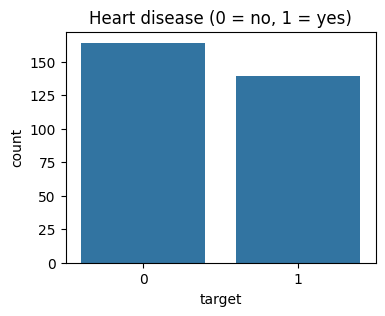

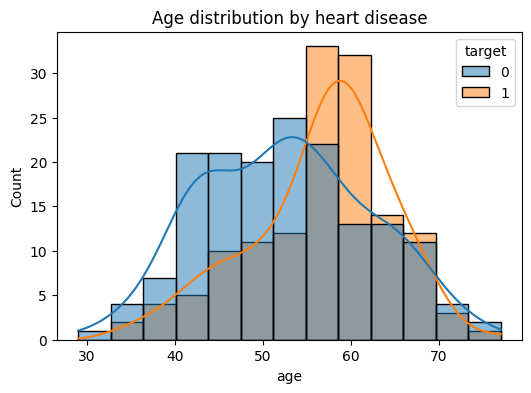

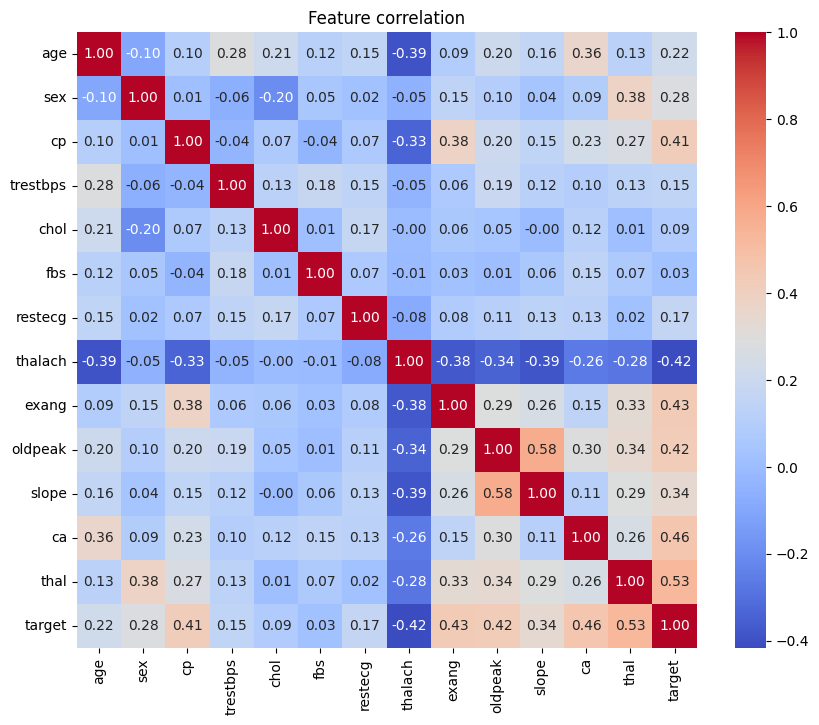

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Summary statistics of every column
print(df.describe().round(2))

# 2. Class balance plot
plt.figure(figsize=(4, 3))
sns.countplot(x="target", data=df)
plt.title("Heart disease (0 = no, 1 = yes)")
plt.show()

# 3. Age distribution by target
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="age", hue="target", kde=True)
plt.title("Age distribution by heart disease")
plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlation")
plt.show()

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd

# 1. Separate features (X) and label (y)
X = df.drop("target", axis=1)
y = df["target"]

# 2. Split: 80% train, 20% test (keeps the same class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

# 3. Three models, each inside a pipeline
models = {
    "Logistic Regression": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Random Forest": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(eval_metric="logloss", random_state=42))
    ]),
}

# 4. 5-fold cross-validation on the TRAINING data only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = {}
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

print(pd.DataFrame(results).T.round(3))

Train: (242, 13)  Test: (61, 13)
                     accuracy  precision  recall     f1  roc_auc
Logistic Regression     0.826      0.844   0.765  0.801    0.896
Random Forest           0.814      0.829   0.756  0.787    0.884
XGBoost                 0.793      0.778   0.774  0.774    0.865


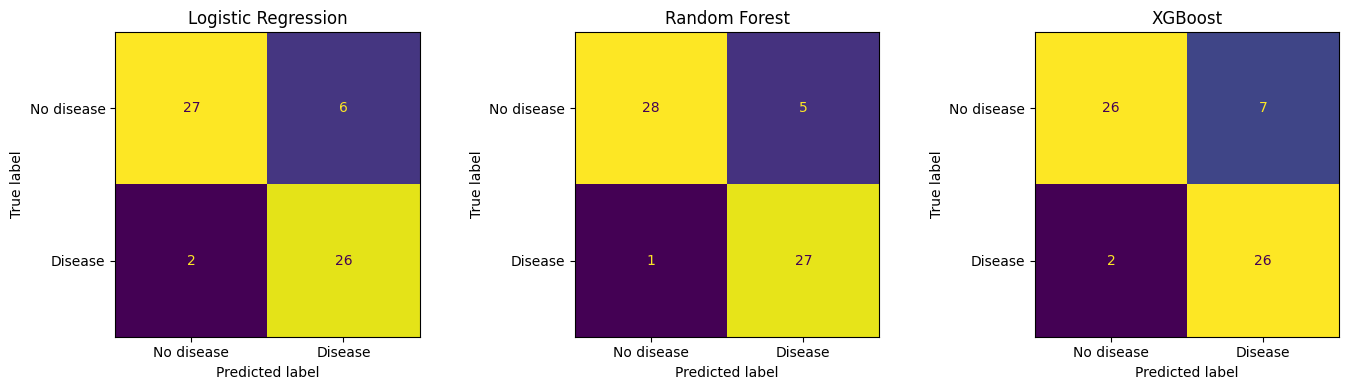

                     accuracy  precision  recall     f1  roc_auc
Logistic Regression     0.869      0.812   0.929  0.867    0.951
Random Forest           0.902      0.844   0.964  0.900    0.955
XGBoost                 0.852      0.788   0.929  0.852    0.919


In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import pandas as pd

test_results = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, pipe) in zip(axes, models.items()):
    # Train on the full training set, then predict the locked test set
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    test_results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
    }

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

print(pd.DataFrame(test_results).T.round(3))

In [8]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
import pandas as pd

# 5-fold CV repeated 10 times = 50 rounds per model
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

summary = {}
for name, pipe in models.items():
    scores = cross_validate(pipe, X, y, cv=rcv, scoring=scoring)
    summary[name] = {
        m: f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}"
        for m in scoring
    }
    print(name, "done")

print()
print(pd.DataFrame(summary).T)

Logistic Regression done
Random Forest done
XGBoost done

                          accuracy      precision         recall  \
Logistic Regression  0.835 ± 0.044  0.846 ± 0.065  0.790 ± 0.072   
Random Forest        0.831 ± 0.045  0.846 ± 0.068  0.779 ± 0.071   
XGBoost              0.801 ± 0.043  0.799 ± 0.062  0.764 ± 0.072   

                                f1        roc_auc  
Logistic Regression  0.814 ± 0.051  0.903 ± 0.036  
Random Forest        0.808 ± 0.051  0.902 ± 0.036  
XGBoost              0.778 ± 0.049  0.877 ± 0.033  


In [9]:
import pandas as pd

path = "/kaggle/input/datasets/alsaniipe/heart-disease/processed.cleveland.data"

columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

df = pd.read_csv(path, header=None, names=columns, na_values="?")
df["target"] = (df["target"] > 0).astype(int)

print(df.shape)
print(df["target"].value_counts())

(303, 14)
target
0    164
1    139
Name: count, dtype: int64


In [10]:
!pip install shap lime

In [11]:
import shap, lime
print("shap", shap.__version__)
print("lime installed")

shap 0.52.0
lime installed


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


Logistic Regression | SHAP shape: (61, 13) | test shape: (61, 13)
Random Forest | SHAP shape: (61, 13) | test shape: (61, 13)
XGBoost | SHAP shape: (61, 13) | test shape: (61, 13)


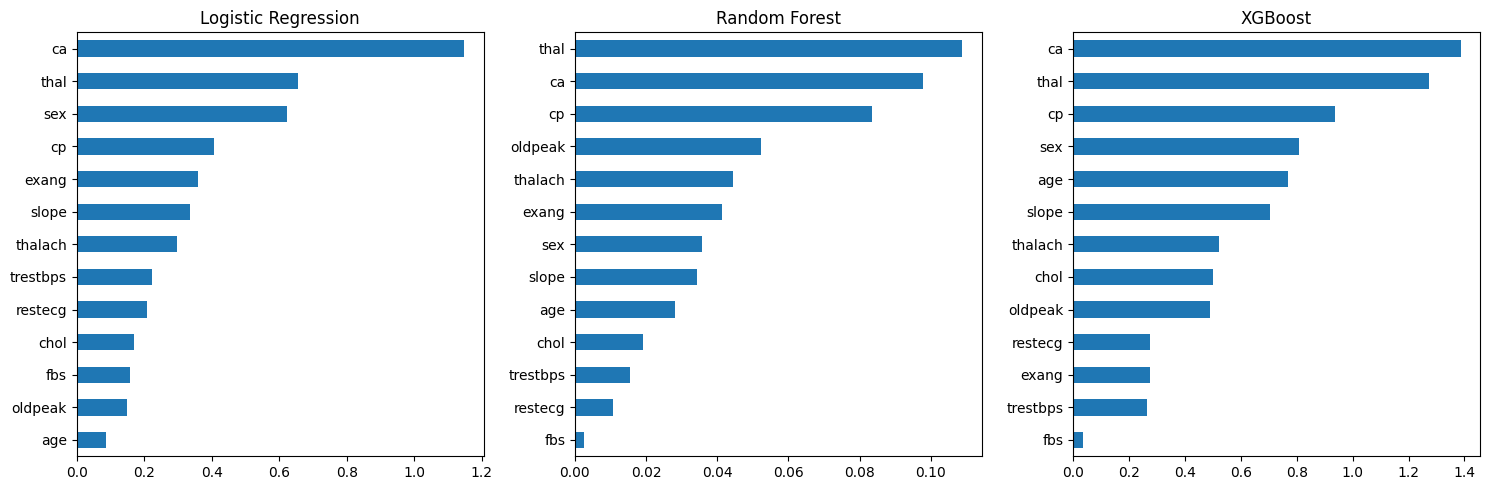

          Logistic Regression  Random Forest  XGBoost
ca                      1.148          0.098    1.386
thal                    0.654          0.109    1.272
sex                     0.621          0.036    0.808
cp                      0.406          0.083    0.936
exang                   0.358          0.041    0.274
slope                   0.334          0.034    0.705
thalach                 0.295          0.044    0.524
trestbps                0.222          0.015    0.264
restecg                 0.208          0.011    0.277
chol                    0.168          0.019    0.501
fbs                     0.158          0.002    0.035
oldpeak                 0.148          0.052    0.491
age                     0.085          0.028    0.768

          Logistic Regression  Random Forest  XGBoost
age                        13              9        5
sex                         3              7        4
cp                          4              3        3
trestbps                   

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

def get_shap(name, pipe):
    pipe.fit(X_train, y_train)
    pre, model = pipe[:-1], pipe[-1]
    Xtr = pd.DataFrame(pre.transform(X_train), columns=X.columns)
    Xte = pd.DataFrame(pre.transform(X_test), columns=X.columns)
    if name == "Logistic Regression":
        explainer = shap.LinearExplainer(model, Xtr)
    else:
        explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(Xte)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.array(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return sv, Xte

shap_store, importance = {}, {}
for name, pipe in models.items():
    sv, Xte = get_shap(name, pipe)
    print(name, "| SHAP shape:", sv.shape, "| test shape:", Xte.shape)
    shap_store[name] = (sv, Xte)
    importance[name] = pd.Series(np.abs(sv).mean(axis=0), index=X.columns)

imp_df = pd.DataFrame(importance)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, imp_df.columns):
    imp_df[name].sort_values().plot.barh(ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

print(imp_df.round(3).sort_values("Logistic Regression", ascending=False))
print()
print(imp_df.rank(ascending=False).astype(int))

In [13]:
import numpy as np
import pandas as pd
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr

lime_imp = {}

for name, pipe in models.items():
    pre, model = pipe[:-1], pipe[-1]
    Xtr = pre.transform(X_train)
    Xte_arr = pre.transform(X_test)

    explainer = LimeTabularExplainer(
        Xtr,
        feature_names=list(X.columns),
        class_names=["No disease", "Disease"],
        mode="classification",
        random_state=42,
    )

    weights = np.zeros((len(Xte_arr), X.shape[1]))
    for i in range(len(Xte_arr)):
        exp = explainer.explain_instance(
            Xte_arr[i], model.predict_proba,
            num_features=X.shape[1], num_samples=1000
        )
        for idx, w in exp.as_map()[1]:
            weights[i, idx] = w

    lime_imp[name] = pd.Series(np.abs(weights).mean(axis=0), index=X.columns)
    print(name, "done")

lime_df = pd.DataFrame(lime_imp)

print("\nLIME importance:")
print(lime_df.round(3).sort_values("Logistic Regression", ascending=False))
print("\nLIME ranks (1 = most important):")
print(lime_df.rank(ascending=False).astype(int))

# ---- Agreement between SHAP and LIME, per model ----
print("\nSHAP vs LIME agreement:")
rows = []
for name in models:
    rho, _ = spearmanr(imp_df[name], lime_df[name])
    top5_shap = set(imp_df[name].nlargest(5).index)
    top5_lime = set(lime_df[name].nlargest(5).index)
    rows.append({"model": name,
                 "spearman_rho": round(rho, 3),
                 "top5_overlap": f"{len(top5_shap & top5_lime)}/5"})
print(pd.DataFrame(rows).set_index("model"))

Logistic Regression done
Random Forest done
XGBoost done

LIME importance:
          Logistic Regression  Random Forest  XGBoost
ca                      0.143          0.173    0.318
thal                    0.108          0.196    0.155
cp                      0.105          0.119    0.146
fbs                     0.086          0.009    0.023
exang                   0.084          0.069    0.068
sex                     0.071          0.085    0.277
thalach                 0.058          0.039    0.052
trestbps                0.046          0.018    0.032
slope                   0.037          0.056    0.110
chol                    0.036          0.023    0.061
restecg                 0.033          0.019    0.031
oldpeak                 0.024          0.061    0.039
age                     0.017          0.029    0.086

LIME ranks (1 = most important):
          Logistic Regression  Random Forest  XGBoost
age                        13              9        6
sex                        

In [14]:
import numpy as np
import pandas as pd
import shap
import itertools
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr

seeds = [1, 2, 3, 4, 5]          # use [1, 2, 3] if it is too slow
feats = list(X.columns)
shap_runs = {n: [] for n in models}
lime_runs = {n: [] for n in models}

for seed in seeds:
    Xtr_df, Xte_df, ytr, yte = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed
    )
    for name, base in models.items():
        pipe = clone(base).fit(Xtr_df, ytr)
        pre, model = pipe[:-1], pipe[-1]
        Xtr = pre.transform(Xtr_df)
        Xte = pre.transform(Xte_df)

        # ---- SHAP ----
        if name == "Logistic Regression":
            expl = shap.LinearExplainer(model, pd.DataFrame(Xtr, columns=feats))
        else:
            expl = shap.TreeExplainer(model)
        sv = expl.shap_values(pd.DataFrame(Xte, columns=feats))
        if isinstance(sv, list):
            sv = sv[1]
        sv = np.array(sv)
        if sv.ndim == 3:
            sv = sv[:, :, 1]
        shap_runs[name].append(pd.Series(np.abs(sv).mean(axis=0), index=feats))

        # ---- LIME (fewer samples to keep it fast) ----
        lime_exp = LimeTabularExplainer(
            Xtr, feature_names=feats, class_names=["No", "Yes"],
            mode="classification", random_state=seed
        )
        w = np.zeros((len(Xte), len(feats)))
        for i in range(len(Xte)):
            e = lime_exp.explain_instance(
                Xte[i], model.predict_proba,
                num_features=len(feats), num_samples=500
            )
            for idx, val in e.as_map()[1]:
                w[i, idx] = val
        lime_runs[name].append(pd.Series(np.abs(w).mean(axis=0), index=feats))

    print("split", seed, "done")

# ---------- 1. Mean rank ± std across splits ----------
def rank_table(runs):
    out = {}
    for name, lst in runs.items():
        ranks = pd.DataFrame(lst).rank(axis=1, ascending=False)
        out[name] = ranks.mean().round(1).astype(str) + " ± " + ranks.std().round(1).astype(str)
    return pd.DataFrame(out)

print("\nSHAP: mean rank ± std (1 = most important)")
print(rank_table(shap_runs))
print("\nLIME: mean rank ± std")
print(rank_table(lime_runs))

# ---------- 2. SHAP vs LIME agreement on each split ----------
print("\nSHAP vs LIME Spearman rho across splits")
rows = []
for name in models:
    rhos = [spearmanr(shap_runs[name][i], lime_runs[name][i])[0]
            for i in range(len(seeds))]
    rows.append({"model": name,
                 "mean_rho": round(np.mean(rhos), 3),
                 "std": round(np.std(rhos), 3)})
print(pd.DataFrame(rows).set_index("model"))

# ---------- 3. Stability of each method across splits ----------
print("\nSplit-to-split stability (mean Spearman between splits)")
rows = []
for name in models:
    for method, runs in [("SHAP", shap_runs), ("LIME", lime_runs)]:
        pairs = [spearmanr(a, b)[0] for a, b in itertools.combinations(runs[name], 2)]
        top3 = sum(set(r.nlargest(3).index) == {"ca", "thal", "cp"} for r in runs[name])
        rows.append({"model": name, "method": method,
                     "stability_rho": round(np.mean(pairs), 3),
                     f"top3=ca,thal,cp": f"{top3}/{len(seeds)}"})
print(pd.DataFrame(rows).set_index(["model", "method"]))

Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.
Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


split 1 done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


split 2 done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


split 3 done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


split 4 done
split 5 done

SHAP: mean rank ± std (1 = most important)
         Logistic Regression Random Forest     XGBoost
age               12.4 ± 0.5     8.8 ± 1.1   5.4 ± 1.3
sex                3.2 ± 0.8     8.2 ± 0.8   5.2 ± 1.1
cp                 4.4 ± 1.5     2.8 ± 0.4   2.0 ± 0.7
trestbps           8.2 ± 0.8    11.4 ± 0.5  10.2 ± 0.8
chol              11.6 ± 1.7    10.2 ± 1.5   7.8 ± 3.6
fbs                9.6 ± 2.6    13.0 ± 0.0  13.0 ± 0.0
restecg            9.6 ± 3.4    11.0 ± 1.0  10.4 ± 2.1
thalach            7.6 ± 0.5     5.2 ± 1.3   8.6 ± 0.9
exang              5.0 ± 1.0     5.2 ± 0.8   9.6 ± 2.6
oldpeak            9.8 ± 0.4     5.2 ± 1.3   7.2 ± 2.8
slope              6.4 ± 1.7     6.8 ± 1.3   7.6 ± 1.7
ca                 1.0 ± 0.0     1.8 ± 0.8   1.4 ± 0.9
thal               2.2 ± 0.4     1.4 ± 0.5   2.6 ± 0.5

LIME: mean rank ± std
         Logistic Regression Random Forest     XGBoost
age               12.0 ± 0.0     9.6 ± 0.5   8.0 ± 1.9
sex                6.8 ± 1.

In [15]:
import os, itertools, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

out = "/kaggle/working/outputs"
os.makedirs(out, exist_ok=True)

# ---------- Load data (Steps 1-2) ----------
path = "/kaggle/input/datasets/alsaniipe/heart-disease/processed.cleveland.data"
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
df = pd.read_csv(path, header=None, names=columns, na_values="?")
df["target"] = (df["target"] > 0).astype(int)
X = df.drop("target", axis=1)
y = df["target"]
feats = list(X.columns)
print("Loaded:", df.shape)

# ---------- Step 4: split, models, 5-fold CV ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42))]),
    "XGBoost": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(eval_metric="logloss", random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
results = {}
for name, pipe in models.items():
    sc = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: sc[f"test_{m}"].mean() for m in scoring}
print("Step 4 done")

# ---------- Step 5: locked test set + confusion matrices ----------
test_results = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pipe) in zip(axes, models.items()):
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_test)
    ypr = pipe.predict_proba(X_test)[:, 1]
    test_results[name] = {
        "accuracy": accuracy_score(y_test, yp),
        "precision": precision_score(y_test, yp),
        "recall": recall_score(y_test, yp),
        "f1": f1_score(y_test, yp),
        "roc_auc": roc_auc_score(y_test, ypr)}
    ConfusionMatrixDisplay(confusion_matrix(y_test, yp),
                           display_labels=["No disease", "Disease"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f"{out}/fig_confusion_matrices.png", dpi=300)
plt.close()
print("Step 5 done")

# ---------- Step 6: repeated 5-fold CV (10 repeats) ----------
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
summary = {}
for name, pipe in models.items():
    sc = cross_validate(pipe, X, y, cv=rcv, scoring=scoring)
    summary[name] = {m: f"{sc[f'test_{m}'].mean():.3f} ± {sc[f'test_{m}'].std():.3f}"
                     for m in scoring}
    print("  Step 6:", name, "done")

# ---------- Step 7: SHAP on the main split ----------
def get_shap(name, pipe):
    pipe.fit(X_train, y_train)
    pre, model = pipe[:-1], pipe[-1]
    Xtr = pd.DataFrame(pre.transform(X_train), columns=feats)
    Xte = pd.DataFrame(pre.transform(X_test), columns=feats)
    if name == "Logistic Regression":
        expl = shap.LinearExplainer(model, Xtr)
    else:
        expl = shap.TreeExplainer(model)
    sv = expl.shap_values(Xte)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.array(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return sv

imp = {}
for name, pipe in models.items():
    sv = get_shap(name, pipe)
    imp[name] = pd.Series(np.abs(sv).mean(axis=0), index=feats)
imp_df = pd.DataFrame(imp)
print("Step 7 done")

# ---------- Step 8: LIME on the main split ----------
lime_imp = {}
for name, pipe in models.items():
    pre, model = pipe[:-1], pipe[-1]
    Xtr = pre.transform(X_train)
    Xte_arr = pre.transform(X_test)
    expl = LimeTabularExplainer(Xtr, feature_names=feats,
                                class_names=["No disease", "Disease"],
                                mode="classification", random_state=42)
    w = np.zeros((len(Xte_arr), len(feats)))
    for i in range(len(Xte_arr)):
        e = expl.explain_instance(Xte_arr[i], model.predict_proba,
                                  num_features=len(feats), num_samples=1000)
        for idx, val in e.as_map()[1]:
            w[i, idx] = val
    lime_imp[name] = pd.Series(np.abs(w).mean(axis=0), index=feats)
    print("  Step 8:", name, "done")
lime_df = pd.DataFrame(lime_imp)

# ---------- Step 9: 5 random splits ----------
seeds = [1, 2, 3, 4, 5]
shap_runs = {n: [] for n in models}
lime_runs = {n: [] for n in models}
for seed in seeds:
    Xtr_df, Xte_df, ytr, yte = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)
    for name, base in models.items():
        pipe = clone(base).fit(Xtr_df, ytr)
        pre, model = pipe[:-1], pipe[-1]
        Xtr = pre.transform(Xtr_df)
        Xte = pre.transform(Xte_df)
        if name == "Logistic Regression":
            expl = shap.LinearExplainer(model, pd.DataFrame(Xtr, columns=feats))
        else:
            expl = shap.TreeExplainer(model)
        sv = expl.shap_values(pd.DataFrame(Xte, columns=feats))
        if isinstance(sv, list):
            sv = sv[1]
        sv = np.array(sv)
        if sv.ndim == 3:
            sv = sv[:, :, 1]
        shap_runs[name].append(pd.Series(np.abs(sv).mean(axis=0), index=feats))

        lexp = LimeTabularExplainer(Xtr, feature_names=feats,
                                    class_names=["No", "Yes"],
                                    mode="classification", random_state=seed)
        w = np.zeros((len(Xte), len(feats)))
        for i in range(len(Xte)):
            e = lexp.explain_instance(Xte[i], model.predict_proba,
                                      num_features=len(feats), num_samples=500)
            for idx, val in e.as_map()[1]:
                w[i, idx] = val
        lime_runs[name].append(pd.Series(np.abs(w).mean(axis=0), index=feats))
    print("  Step 9: split", seed, "done")

def rank_table(runs):
    o = {}
    for name, lst in runs.items():
        r = pd.DataFrame(lst).rank(axis=1, ascending=False)
        o[name] = r.mean().round(1).astype(str) + " ± " + r.std().round(1).astype(str)
    return pd.DataFrame(o)

# ---------- Save everything (Step 10) ----------
pd.DataFrame(results).T.round(3).to_csv(f"{out}/table1_cv_5fold.csv")
pd.DataFrame(test_results).T.round(3).to_csv(f"{out}/table2_test_set.csv")
pd.DataFrame(summary).T.to_csv(f"{out}/table3_repeated_cv.csv")
imp_df.round(4).to_csv(f"{out}/table4_shap_importance.csv")
imp_df.rank(ascending=False).astype(int).to_csv(f"{out}/table4_shap_ranks.csv")
lime_df.round(4).to_csv(f"{out}/table5_lime_importance.csv")
lime_df.rank(ascending=False).astype(int).to_csv(f"{out}/table5_lime_ranks.csv")
rank_table(shap_runs).to_csv(f"{out}/table6_shap_rank_across_splits.csv")
rank_table(lime_runs).to_csv(f"{out}/table7_lime_rank_across_splits.csv")

rows = []
for name in models:
    rhos = [spearmanr(shap_runs[name][i], lime_runs[name][i])[0] for i in range(len(seeds))]
    rows.append({"model": name, "mean_rho": round(np.mean(rhos), 3), "std": round(np.std(rhos), 3)})
agreement = pd.DataFrame(rows).set_index("model")
agreement.to_csv(f"{out}/table8_shap_lime_agreement.csv")

rows = []
for name in models:
    for method, runs in [("SHAP", shap_runs), ("LIME", lime_runs)]:
        pairs = [spearmanr(a, b)[0] for a, b in itertools.combinations(runs[name], 2)]
        rows.append({"model": name, "method": method, "stability_rho": round(np.mean(pairs), 3)})
stability = pd.DataFrame(rows).set_index(["model", "method"])
stability.to_csv(f"{out}/table9_stability.csv")

for tag, d in [("shap", imp_df), ("lime", lime_df)]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, name in zip(axes, d.columns):
        d[name].sort_values().plot.barh(ax=ax)
        ax.set_title(f"{tag.upper()} importance: {name}")
    plt.tight_layout()
    plt.savefig(f"{out}/fig_{tag}_importance.png", dpi=300)
    plt.close()

shutil.make_archive("/kaggle/working/heart_project_outputs", "zip", out)

print("\nSaved files:", sorted(os.listdir(out)))
print("\nRepeated CV table:\n", pd.DataFrame(summary).T)
print("\nSHAP-LIME agreement:\n", agreement)
print("\nStability:\n", stability)

Loaded: (303, 14)
Step 4 done
Step 5 done
  Step 6: Logistic Regression done
  Step 6: Random Forest done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


  Step 6: XGBoost done
Step 7 done
  Step 8: Logistic Regression done
  Step 8: Random Forest done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


  Step 8: XGBoost done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


... (3 outputs left out)

Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


  Step 9: split 3 done


Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


  Step 9: split 4 done
  Step 9: split 5 done

Saved files: ['fig_confusion_matrices.png', 'fig_lime_importance.png', 'fig_shap_importance.png', 'table1_cv_5fold.csv', 'table2_test_set.csv', 'table3_repeated_cv.csv', 'table4_shap_importance.csv', 'table4_shap_ranks.csv', 'table5_lime_importance.csv', 'table5_lime_ranks.csv', 'table6_shap_rank_across_splits.csv', 'table7_lime_rank_across_splits.csv', 'table8_shap_lime_agreement.csv', 'table9_stability.csv']

Repeated CV table:
                           accuracy      precision         recall  \
Logistic Regression  0.835 ± 0.044  0.846 ± 0.065  0.790 ± 0.072   
Random Forest        0.831 ± 0.045  0.846 ± 0.068  0.779 ± 0.071   
XGBoost              0.801 ± 0.043  0.799 ± 0.062  0.764 ± 0.072   

                                f1        roc_auc  
Logistic Regression  0.814 ± 0.051  0.903 ± 0.036  
Random Forest        0.808 ± 0.051  0.902 ± 0.036  
XGBoost              0.778 ± 0.049  0.877 ± 0.033  

SHAP-LIME agreement:
               

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = "/kaggle/input/datasets/alsaniipe/heart-disease/processed.cleveland.data"
cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]
df = pd.read_csv(path, header=None, names=cols, na_values="?")
df["target"] = (df["target"] > 0).astype(int)

# Figure with class balance and age distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="target", data=df, ax=axes[0])
axes[0].set_title("(a) Class balance (0 = no disease, 1 = disease)")
sns.histplot(data=df, x="age", hue="target", kde=True, ax=axes[1])
axes[1].set_title("(b) Age distribution by class")
plt.tight_layout()
plt.savefig("/kaggle/working/fig_dataset_overview.png", dpi=300)
plt.close()

# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between features and target")
plt.tight_layout()
plt.savefig("/kaggle/working/fig_correlation.png", dpi=300)
plt.close()
print("saved")

saved
